# 01 - Data overview
First look at every ShopSmart dataset. Datasets are loaded **by name** from the map in `configs/config.yaml`,
so no file paths are hard-coded. See `data/raw/DATA_CARD.md` for every column.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))   # lets the notebook import the shopsmart package

import pandas as pd
import matplotlib.pyplot as plt
from shopsmart.config import PROJECT_ROOT, dataset_path
from shopsmart.data import load, load_all, list_datasets

pd.set_option("display.max_columns", 30)
print("Project root:", PROJECT_ROOT)
list_datasets()

Project root: C:\Smart_shopping_EPA


,file,rows,exists,evaluation_only,description
name,,,,,
products,products.csv,1500,True,False,"Product catalogue (1,500 products, 9 categorie..."
users,user_data.csv,5000,True,False,"Customer profiles (5,000 customers)"
interactions,interaction.csv,354340,True,False,"Event log - views, clicks, carts, purchases, r..."
reviews,reviews.csv,7243,True,False,Written product reviews with 1-5 star ratings ...
search_queries,search_queries.csv,515,True,False,Labelled search queries for evaluating keyword...
chatbot_intents,chatbot_intents.csv,2560,True,False,Chatbot utterances labelled with 16 intents an...
faq,faq.csv,16,True,False,Shop policy questions and answers for the chatbot
personas_truth,customer_personas_truth.csv,5000,True,True,HIDDEN true persona per customer - use ONLY to...


## Load everything

In [2]:
data = load_all()          # dict: name -> DataFrame (the hidden personas file is excluded on purpose)
for name, df in data.items():
    print(f"{name:16s} {df.shape[0]:>8,} rows x {df.shape[1]:>2} cols")
products, users, interactions = data["products"], data["users"], data["interactions"]
reviews, queries, intents, faq = data["reviews"], data["search_queries"], data["chatbot_intents"], data["faq"]

products            1,500 rows x 18 cols
users               5,000 rows x  9 cols
interactions      354,340 rows x 10 cols
reviews             7,243 rows x  8 cols
search_queries        515 rows x  4 cols
chatbot_intents     2,560 rows x  5 cols
faq                    16 rows x  3 cols


In [3]:
products.head(3)

,Product ID,Product Name,Category,Product Type,Brand,Description,Price,Colour,Size,Material,Age Range,Tags,Avg Rating,Num Reviews,In Stock,Stock Qty,Delivery Days,Launch Date
0,0,VoltEdge Ultra Wireless Earbuds,Electronics,Wireless Earbuds,VoltEdge,The VoltEdge Ultra Wireless Earbuds are design...,87.38,Graphite,NaN,Recycled plastic,Adult,"audio, fitness, gadget, music, tech",4.3,3,False,0,1,2025-11-04
1,1,SonicWave Lite Noise-Cancelling Headphones,Electronics,Noise-Cancelling Headphones,SonicWave,The SonicWave Lite Noise-Cancelling Headphones...,87.57,Midnight Blue,NaN,Aluminium,Adult,"audio, gadget, music, tech, travel",3.0,1,True,187,1,2025-11-18
2,2,PulseGear Ultra Bluetooth Speaker,Electronics,Bluetooth Speaker,PulseGear,Looking for a dependable bluetooth speaker? Th...,122.74,Midnight Blue,NaN,ABS plastic,Adult,"audio, gadget, outdoor, party, tech",3.0,2,True,204,3,2026-03-05


In [4]:
users.head(3)

,User ID,Age,Gender,Location,Signup Date,Preferred Device,Newsletter,Browsing History,Purchase History
0,0,40,Female,Glasgow,2022-10-12,Desktop,False,"Bedding & Linens, Toys, Food, Books, Electronics","477, 825, 310, 444, 192, 174, 1217, 88, 954, 638"
1,1,30,Male,Chicago,2025-12-12,Desktop,False,"Bedding & Linens, Home & Kitchen, Fashion","851, 1451"
2,2,36,Female,Chicago,2023-01-19,Desktop,True,"Bedding & Linens, Fashion, Beauty, Home & Kitchen","1354, 737, 792, 931, 587, 1063, 1040, 754, 124..."


In [5]:
interactions.head(10)

,Event ID,User ID,Product ID,Session ID,Interaction Type,Timestamp,Rating,Device,Quantity,Price
0,1,3794,1145,32868,view,2024-11-01 00:07:10,<NA>,Tablet,<NA>,NaN
1,2,3794,1145,32868,click,2024-11-01 00:08:05,<NA>,Tablet,<NA>,NaN
2,3,3794,35,32868,view,2024-11-01 00:10:11,<NA>,Tablet,<NA>,NaN
3,4,3794,420,32868,view,2024-11-01 00:11:11,<NA>,Tablet,<NA>,NaN
4,5,1797,157,15474,view,2024-11-01 00:13:56,<NA>,Mobile,<NA>,NaN
5,6,1797,640,15474,view,2024-11-01 00:17:35,<NA>,Mobile,<NA>,NaN
6,7,1797,344,15474,view,2024-11-01 00:19:39,<NA>,Mobile,<NA>,NaN
7,8,1797,825,15474,view,2024-11-01 00:23:01,<NA>,Mobile,<NA>,NaN
8,9,737,1090,6247,view,2024-11-01 00:30:33,<NA>,Mobile,<NA>,NaN
9,10,737,1164,6247,view,2024-11-01 00:32:51,<NA>,Mobile,<NA>,NaN


In [9]:
# Top 5 Records of all data sets 
datasets = {"Products": products, "Users": users, "Interactions": interactions}

for name, df in datasets.items():
    print(f"\n===== {name}: {df.shape[0]:,} rows x {df.shape[1]} columns =====")
    print("Top 5 records:")
    display(df.head(5))
    print("Bottom 5 records:")
    display(df.tail(5))


===== Products: 1,500 rows x 18 columns =====
Top 5 records:


,Product ID,Product Name,Category,Product Type,Brand,Description,Price,Colour,Size,Material,Age Range,Tags,Avg Rating,Num Reviews,In Stock,Stock Qty,Delivery Days,Launch Date
0,0,VoltEdge Ultra Wireless Earbuds,Electronics,Wireless Earbuds,VoltEdge,The VoltEdge Ultra Wireless Earbuds are design...,87.38,Graphite,NaN,Recycled plastic,Adult,"audio, fitness, gadget, music, tech",4.3,3,False,0,1,2025-11-04
1,1,SonicWave Lite Noise-Cancelling Headphones,Electronics,Noise-Cancelling Headphones,SonicWave,The SonicWave Lite Noise-Cancelling Headphones...,87.57,Midnight Blue,NaN,Aluminium,Adult,"audio, gadget, music, tech, travel",3.0,1,True,187,1,2025-11-18
2,2,PulseGear Ultra Bluetooth Speaker,Electronics,Bluetooth Speaker,PulseGear,Looking for a dependable bluetooth speaker? Th...,122.74,Midnight Blue,NaN,ABS plastic,Adult,"audio, gadget, outdoor, party, tech",3.0,2,True,204,3,2026-03-05
3,3,SonicWave Air Smartwatch,Electronics,Smartwatch,SonicWave,Looking for a dependable smartwatch? The Sonic...,129.12,Graphite,NaN,ABS plastic,Adult,"fitness, gadget, health, tech, wearable",2.7,3,True,21,1,2024-06-05
4,4,NexaTech Pro Power Bank,Electronics,Power Bank,NexaTech,NexaTech's pro power bank brings quality and v...,28.55,Silver,NaN,ABS plastic,Adult,"charging, gadget, tech, travel",3.9,8,True,125,1,2025-04-06


Bottom 5 records:


,Product ID,Product Name,Category,Product Type,Brand,Description,Price,Colour,Size,Material,Age Range,Tags,Avg Rating,Num Reviews,In Stock,Stock Qty,Delivery Days,Launch Date
1495,1495,Ovenly Compact Glass Food Containers,Home & Kitchen,Glass Food Containers,Ovenly,Ovenly's compact glass food containers bring q...,19.99,Cream,NaN,Borosilicate glass,Adult,"home, kitchen, meal prep, storage",4.0,2,True,118,3,2026-03-30
1496,1496,BrewMaster Pro Spice Rack,Home & Kitchen,Spice Rack,BrewMaster,Make family meals easier with the BrewMaster P...,40.75,Cream,NaN,Bamboo,Adult,"home, kitchen, organisation, storage",4.2,4,True,180,5,2024-02-09
1497,1497,LinenLuxe Cozy Fitted Sheet Set,Bedding & Linens,Fitted Sheet Set,LinenLuxe,LinenLuxe's cozy fitted sheet set brings quali...,65.59,Oatmeal,King,Bamboo lyocell,All ages,"bedding, bedroom, home",5.0,1,True,20,2,2025-09-07
1498,1498,Petal & Co Gentle Hydrating Face Cream,Beauty,Hydrating Face Cream,Petal & Co,Looking for a dependable hydrating face cream?...,59.99,NaN,50 ml,NaN,Adult,"beauty, self-care, skincare",3.3,3,True,91,4,2024-06-08
1499,1499,DreamWeave Cozy Duvet Cover Set,Bedding & Linens,Duvet Cover Set,DreamWeave,"Meet the DreamWeave Cozy Duvet Cover Set, a co...",40.39,Dove grey,Single,Bamboo lyocell,All ages,"bedding, bedroom, home",2.7,3,True,235,3,2024-02-24



===== Users: 5,000 rows x 9 columns =====
Top 5 records:


,User ID,Age,Gender,Location,Signup Date,Preferred Device,Newsletter,Browsing History,Purchase History
0,0,40,Female,Glasgow,2022-10-12,Desktop,False,"Bedding & Linens, Toys, Food, Books, Electronics","477, 825, 310, 444, 192, 174, 1217, 88, 954, 638"
1,1,30,Male,Chicago,2025-12-12,Desktop,False,"Bedding & Linens, Home & Kitchen, Fashion","851, 1451"
2,2,36,Female,Chicago,2023-01-19,Desktop,True,"Bedding & Linens, Fashion, Beauty, Home & Kitchen","1354, 737, 792, 931, 587, 1063, 1040, 754, 124..."
3,3,23,Male,Edinburgh,2023-11-23,Desktop,False,"Fashion, Books, Electronics, Sports, Bedding &...","850, 575"
4,4,45,Other,Melbourne,2025-06-08,Mobile,False,"Fashion, Food, Sports","154, 832, 591, 1335, 474, 167, 320, 1081, 54"


... (2 outputs left out)


===== Interactions: 354,340 rows x 10 columns =====
Top 5 records:


,Event ID,User ID,Product ID,Session ID,Interaction Type,Timestamp,Rating,Device,Quantity,Price
0,1,3794,1145,32868,view,2024-11-01 00:07:10,<NA>,Tablet,<NA>,NaN
1,2,3794,1145,32868,click,2024-11-01 00:08:05,<NA>,Tablet,<NA>,NaN
2,3,3794,35,32868,view,2024-11-01 00:10:11,<NA>,Tablet,<NA>,NaN
3,4,3794,420,32868,view,2024-11-01 00:11:11,<NA>,Tablet,<NA>,NaN
4,5,1797,157,15474,view,2024-11-01 00:13:56,<NA>,Mobile,<NA>,NaN


Bottom 5 records:


,Event ID,User ID,Product ID,Session ID,Interaction Type,Timestamp,Rating,Device,Quantity,Price
354335,354336,4331,122,37487,click,2026-10-31 23:13:05,<NA>,Tablet,<NA>,NaN
354336,354337,3484,592,30148,view,2026-10-31 23:13:22,<NA>,Mobile,<NA>,NaN
354337,354338,4331,352,37487,view,2026-10-31 23:13:50,<NA>,Tablet,<NA>,NaN
354338,354339,3484,592,30148,click,2026-10-31 23:14:49,<NA>,Mobile,<NA>,NaN
354339,354340,3484,254,30148,view,2026-10-31 23:16:28,<NA>,Mobile,<NA>,NaN


## How the tables connect

In [6]:
print("Interactions link to", interactions["User ID"].nunique(), "users and", interactions["Product ID"].nunique(), "products")
print("Sessions:", interactions["Session ID"].nunique(), "| date range:",
      interactions["Timestamp"].min().date(), "->", interactions["Timestamp"].max().date())
interactions["Interaction Type"].value_counts()

Interactions link to 4932 users and 1500 products
Sessions: 43111 | date range: 2024-11-01 -> 2026-10-31


Interaction Type
view           187026
click           91750
add_to_cart     38597
purchase        21847
rating           9660
wishlist         5460
Name: count, dtype: int64

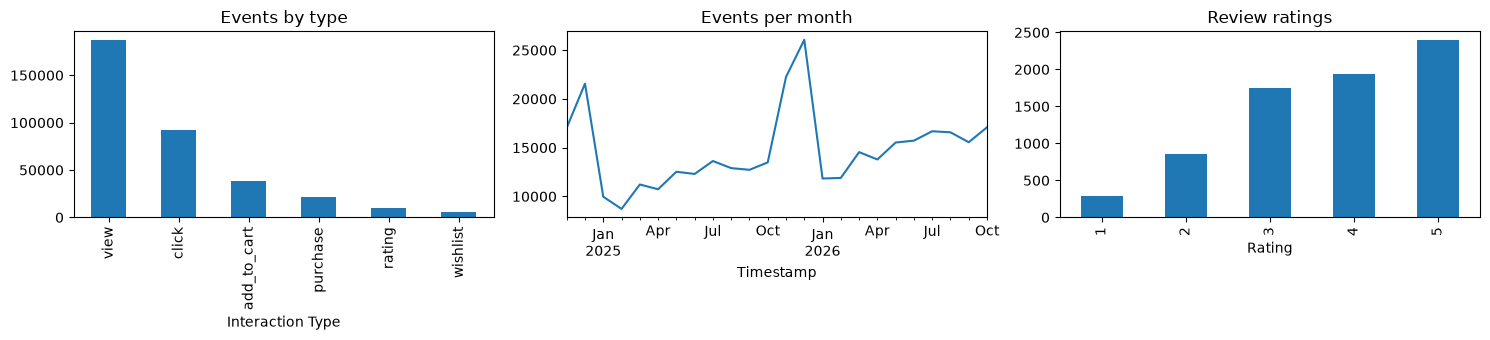

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
interactions["Interaction Type"].value_counts().plot.bar(ax=ax[0], title="Events by type")
interactions.set_index("Timestamp").resample("ME").size().plot(ax=ax[1], title="Events per month")
reviews["Rating"].value_counts().sort_index().plot.bar(ax=ax[2], title="Review ratings")
plt.tight_layout(); plt.show()

## Text datasets for the chatbot

In [8]:
display(queries.groupby("Query Type").size().rename("queries"))
display(intents["Intent"].value_counts().head())
intents.sample(5, random_state=1)[["Text", "Intent", "Entities"]]

Query Type
filtered_brand      90
filtered_colour     62
filtered_price      88
gift                 5
keyword             90
semantic           180
Name: queries, dtype: int64

Intent
faq_delivery        160
out_of_scope        160
similar_products    160
faq_payment         160
filter_refine       160
Name: count, dtype: int64

,Text,Intent,Entities
1395,what shuold I buy next?,personal_recommendation,{}
2488,track ym order,order_tracking,{}
425,hey do you have i tin white :),filter_refine,"{""colour"": ""white""}"
1654,"hi, thank you thank you",thanks,{}
1710,"i like the modo essential denim jacket, what e...",similar_products,"{""product"": ""Modo Essential Denim Jacket""}"


## Next steps
- Run the data checks: `python -m shopsmart.data.validate` (or the **Validate data** task in VS Code)
- `02_eda.ipynb`: deeper exploration (long tail, seasonality, funnel, personas)